### Kassiopeia – Lösung Schritt für Schritt

*34. Bundeswettbewerb Informatik (2015), 1. Runde, Junioraufgabe 2*

In Quadratien ist das Land in schwarze und weiße quadratische Felder einheitlicher Größe aufgeteilt. Auf jedem weißen Feld steht
eine Pflanze, aus der täglich ein Blatt sprießt.

Die Schildkröte Kassiopeia lebt schon seit vielen Jahren von diesen Blättern.

Jeden Tag muss sie alle Blätter fressen, um zu überleben. Also muss sie jedes weiße Feld besuchen. Die schwarzen Felder heizen
sich unter der Sonne so sehr auf, dass sie diese nicht betreten kann. Von einem weißen Feld kann sie in einem Schritt zu jedem
in nördlicher, südlicher, östlicher oder westlicher Richtung benachbarten weißen Feld gelangen.

#### Junioraufgabe 2

Schreibe ein Programm, das für eine Version von Quadratien ausgibt, ob Kassiopeia alle weißen Felder erreichen kann, ohne ein
schwarzes Feld zu überqueren.

Für das folgende Beispiel ist die richtige Ausgabe „Ja“.

```
6 9
#########
#  #    #
#  # #  #
#  K #  #
#    #  #
#########
```

Wende dein Programm mindestens auf die Beispiele an, die du unter bundeswettbewerb-informatik.de findest, und dokumentiere
jeweils das Ergebnis.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `kassiopeia0.txt` bis `kassiopeia7.txt` (`kassiopeia0.txt` ist das Beispiel oben). Die erste Zeile enthält die Anzahl der Zeilen und Spalten,
dann folgt das Gelände: `#` ist ein schwarzes Feld, ein Leerzeichen ein weißes Feld, `K` ist Kassiopeia (auch auf einem weißen Feld). `kassiopeia7.txt` ist eine **leere Datei**.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Raster als Liste von Zeilen:** `welt[z][s]` ist das Zeichen in Zeile `z` und Spalte `s`. Die vier Nachbarn eines Feldes sind `(z−1, s)`, `(z+1, s)`, `(z, s−1)` und `(z, s+1)`.
- **Graph und Zusammenhang:** Jedes weiße Feld ist ein Knoten, benachbarte weiße Felder sind durch eine Kante verbunden. Kassiopeia kann alle Felder erreichen, wenn dieser Graph **zusammenhängend** ist.
- **Breitensuche oder Tiefensuche (Flood Fill):** Von einem Startfeld aus besucht man der Reihe nach alle erreichbaren Felder. Man merkt sich, welche Felder schon besucht sind, damit man keines zweimal bearbeitet.
  Eine Liste von „noch zu untersuchenden Feldern“ steuert den Ablauf: nimmt man immer das erste Feld, ist es eine Breitensuche, nimmt man das letzte, eine Tiefensuche.
- **Der Startpunkt ist egal:** Die Felder, die Kassiopeia erreichen kann, sind genau die Felder der Zusammenhangskomponente. Geht es von A nach B, geht es auch von B nach A. Wir starten darum bei irgendeinem weißen Feld
  (dem Feld `K` oder dem ersten gefundenen).
- **Sonderfälle:** Eine leere Datei, Wälder ohne weißes Feld, ein fehlendes `K`.

**Nützliche Funktionen und Bibliotheken**
- `str.ljust`, `split`, `in`, `append`, `pop`, Listen von Listen, `set`
- Für die Zeichnung: `matplotlib.pyplot` (optional)

## Die Idee

1. Das Gelände einlesen und alle weißen Felder zählen.
2. Bei einem weißen Feld starten (mit einer Liste `offen`, in der zuerst nur dieses Feld steht).
3. Solange die Liste nicht leer ist: ein Feld herausnehmen. Seine vier Nachbarn ansehen. Ist ein Nachbar weiß und noch nicht besucht, merken wir ihn als besucht und hängen ihn an die Liste an.
4. Am Ende vergleichen wir die Zahl der besuchten mit der Zahl aller weißen Felder. Sind es gleich viele, lautet die Antwort „Ja“, sonst „Nein“.

## Schritt 1: Das Gelände einlesen

Die erste Zeile gibt Zeilen- und Spaltenzahl an, die folgenden Zeilen sind das Gelände. Wir lesen die ganze Datei, zerlegen sie in Zeilen (`splitlines`) und merken uns die Zeilen des Geländes.
Falls eine Zeile kürzer ist als die Breite (zum Beispiel, weil ein Editor Leerzeichen am Ende entfernt hat), füllen wir sie mit `ljust` mit `#` auf, denn außerhalb des Geländes gibt es nichts zu betreten.
Eine **leere Datei** (`kassiopeia7.txt`) liefert eine leere Welt: `[]`.

In [ ]:
def lies_welt(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        zeilen = f.read().splitlines()
    if len(zeilen) == 0:
        return []                                   # leere Datei
    anzahl_zeilen, anzahl_spalten = zeilen[0].split()
    anzahl_zeilen = int(anzahl_zeilen)
    anzahl_spalten = int(anzahl_spalten)
    welt = []
    for z in range(anzahl_zeilen):
        zeile = zeilen[1 + z] if 1 + z < len(zeilen) else ''
        welt.append(zeile.ljust(anzahl_spalten, '#'))
    return welt


welt = lies_welt('beispieldaten/kassiopeia0.txt')
for zeile in welt:
    print('|' + zeile + '|')
print(len(lies_welt('beispieldaten/kassiopeia7.txt')), 'Zeilen in kassiopeia7.txt')

|#########|
|#  #    #|
|#  # #  #|
|#  K #  #|
|#    #  #|
|#########|
0 Zeilen in kassiopeia7.txt


## Schritt 2: Die weißen Felder

Ein Feld ist weiß, wenn dort kein `#` steht (also Leerzeichen oder `K`). `ist_weiss(welt, z, s)` prüft zusätzlich, ob die Position **im Gelände** liegt. Außerhalb ist nichts begehbar. So müssen wir später
am Rand nichts Besonderes tun.

`alle_weissen(welt)` sammelt alle weißen Felder als Paare `(Zeile, Spalte)`.

In [ ]:
def ist_weiss(welt, z, s):
    if z < 0 or z >= len(welt) or s < 0 or s >= len(welt[0]):
        return False
    return welt[z][s] != '#'


def alle_weissen(welt):
    weisse = []
    for z in range(len(welt)):
        for s in range(len(welt[0])):
            if ist_weiss(welt, z, s):
                weisse.append((z, s))
    return weisse


print(len(alle_weissen(welt)), 'weiße Felder')

23 weiße Felder


## Schritt 3: Von einem Feld aus alles besuchen

`erreichbare(welt, start)` macht die Suche aus der Idee. In der Menge `besucht` stehen alle Felder, die wir schon entdeckt haben (`set` prüft sehr schnell, ob ein Feld darin vorkommt). Die Liste `offen` enthält die Felder,
deren Nachbarn wir noch ansehen müssen. `offen.pop()` nimmt das **letzte** Feld heraus.

Die vier Nachbarn entstehen aus den Schritten `(-1, 0)`, `(1, 0)`, `(0, -1)` und `(0, 1)` (oben, unten, links, rechts, **nicht** diagonal).

In [ ]:
def erreichbare(welt, start):
    besucht = {start}
    offen = [start]
    while len(offen) > 0:
        z, s = offen.pop()
        for dz, ds in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nachbar = (z + dz, s + ds)
            if ist_weiss(welt, nachbar[0], nachbar[1]) and nachbar not in besucht:
                besucht.add(nachbar)
                offen.append(nachbar)
    return besucht


weisse = alle_weissen(welt)
besucht = erreichbare(welt, weisse[0])
print(len(besucht), 'von', len(weisse), 'weißen Feldern erreichbar')

23 von 23 weißen Feldern erreichbar


## Schritt 4: Die Antwort

Wir starten bei **irgendeinem** weißen Feld, am besten bei Kassiopeias eigenem Feld `K`, falls es eines gibt (sonst beim ersten weißen Feld). Der Startpunkt ist für die Antwort unwichtig,
wie oben erklärt. Sind alle weißen Felder erreichbar, antworten wir „Ja“, sonst „Nein“.

Sonderfälle: Gibt es **gar kein** weißes Feld (zum Beispiel bei der leeren Datei), muss Kassiopeia nichts besuchen, die Antwort ist „Ja“ (so steht es auch in den Lösungshinweisen).

In [ ]:
def finde_start(welt):
    for z in range(len(welt)):
        for s in range(len(welt[0])):
            if welt[z][s] == 'K':
                return (z, s)
    weisse = alle_weissen(welt)
    if len(weisse) == 0:
        return None
    return weisse[0]


def kann_alles_erreichen(welt):
    if len(welt) == 0:
        return True, []
    weisse = alle_weissen(welt)
    if len(weisse) == 0:
        return True, []
    erreichbar = erreichbare(welt, finde_start(welt))
    nicht_erreichbar = []
    for feld in weisse:
        if feld not in erreichbar:
            nicht_erreichbar.append(feld)
    return len(nicht_erreichbar) == 0, nicht_erreichbar


for nr in range(8):
    welt = lies_welt(f'beispieldaten/kassiopeia{nr}.txt')
    ja, nicht = kann_alles_erreichen(welt)
    weisse = len(alle_weissen(welt))
    text = 'Ja' if ja else 'Nein'
    print(f'kassiopeia{nr}.txt: {text}  ({weisse} weiße Felder, {len(nicht)} nicht erreichbar)')

kassiopeia0.txt: Ja  (23 weiße Felder, 0 nicht erreichbar)
kassiopeia1.txt: Nein  (36 weiße Felder, 17 nicht erreichbar)
kassiopeia2.txt: Ja  (15 weiße Felder, 0 nicht erreichbar)
kassiopeia3.txt: Ja  (18 weiße Felder, 0 nicht erreichbar)
kassiopeia4.txt: Ja  (13 weiße Felder, 0 nicht erreichbar)
kassiopeia5.txt: Ja  (13 weiße Felder, 0 nicht erreichbar)
kassiopeia6.txt: Ja  (11 weiße Felder, 0 nicht erreichbar)
kassiopeia7.txt: Ja  (0 weiße Felder, 0 nicht erreichbar)


Das stimmt mit der Tabelle der offiziellen Lösungshinweise überein: nur `kassiopeia1.txt` ist „Nein“, alle anderen „Ja“ (auch die leere Datei 7).
Bei `kassiopeia4.txt` und `kassiopeia5.txt` ist die Welt ein langer Gang (ein Streifen mit 13 weißen Feldern). Kassiopeia steht in einem Fall am Anfang, im anderen am Ende, und beide Male erreicht sie alles.

## Für Neugierige: Welche Felder sind nicht erreichbar?

Für ein „Nein“ ist es nützlich zu sehen, **welche** Felder fehlen. Wir zeichnen die Welt: schwarz = `#`, grün = erreichbar, rot = weiß, aber nicht erreichbar. Als Test zeigen wir `kassiopeia1.txt` und `kassiopeia6.txt`.
Die nicht erreichbaren Felder hat `kann_alles_erreichen` bereits berechnet.

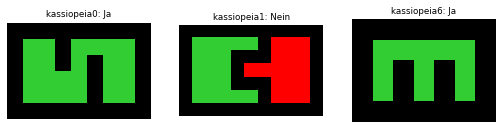

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


def zeichne(nr, achse):
    welt = lies_welt(f'beispieldaten/kassiopeia{nr}.txt')
    ja, nicht = kann_alles_erreichen(welt)
    bild = []
    for z in range(len(welt)):
        zeile = []
        for s in range(len(welt[0])):
            if welt[z][s] == '#':
                zeile.append(0)
            elif (z, s) in nicht:
                zeile.append(2)
            else:
                zeile.append(1)
        bild.append(zeile)
    achse.imshow(bild, cmap=ListedColormap(['black', 'limegreen', 'red']), vmin=0, vmax=2)
    achse.set_title(f'kassiopeia{nr}: ' + ('Ja' if ja else 'Nein'), fontsize=9)
    achse.axis('off')


bild, achsen = plt.subplots(1, 3, figsize=(9, 3))
zeichne(0, achsen[0])
zeichne(1, achsen[1])
zeichne(6, achsen[2])
plt.show()

Bei `kassiopeia1.txt` sind die roten Felder durch schwarze Wände vom Rest getrennt. Solche abgetrennten Bereiche heißen in der Graphentheorie weitere **Zusammenhangskomponenten**.
Man kann auch die Zahl der Komponenten zählen: Man startet bei jedem noch nicht besuchten weißen Feld eine neue Suche (das wäre eine weitere Aufgabe).